# FIFA World Cup 2026 – Objective 1

## Task 2: Disciplinary Behaviour

**Team Member:** Kshitiz Singh  
**Student ID:** S396376

### Analytic Question

Did UEFA teams receive a different average number of total cards compared with non-UEFA teams during the FIFA World Cup 2026?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


### 2. Data Loading

The FIFA World Cup 2026 discipline statistics dataset is loaded using pandas. The dataset contains team-level disciplinary statistics from the tournament.

In [2]:
df = pd.read_csv("../data/raw/FIFA_2026_Discipline_Statistics.csv")

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully.
Number of rows: 48
Number of columns: 8


,Rank,Team,Fouls Against,Fouls For,Yellow Cards,Red Cards,Indirect Red Cards,Offsides
0,1,Argentina,113,100,15,1,1,22
1,2,Spain,101,89,6,0,0,21
2,3,Switzerland,87,89,8,1,1,13
3,4,France,84,74,6,0,0,14
4,5,England,81,116,8,1,0,15


## 3. Data Quality Check

Before conducting the analysis, the dataset is checked for column names, data types, missing values, and duplicate rows.

In [3]:
# Display column names
print("Column names:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Column names:
['Rank', 'Team', 'Fouls Against', 'Fouls For', 'Yellow Cards', 'Red Cards', 'Indirect Red Cards', 'Offsides']

Data types:
Rank                  int64
Team                    str
Fouls Against         int64
Fouls For             int64
Yellow Cards          int64
Red Cards             int64
Indirect Red Cards    int64
Offsides              int64
dtype: object

Missing values:
Rank                  0
Team                  0
Fouls Against         0
Fouls For             0
Yellow Cards          0
Red Cards             0
Indirect Red Cards    0
Offsides              0
dtype: int64

Number of duplicate rows: 0


### Data Quality Result

The dataset contains 48 teams and 8 variables. No missing values or duplicate rows were identified. The disciplinary variables, including **Yellow Cards**, **Red Cards**, and **Indirect Red Cards**, are stored as numeric variables. Therefore, no rows need to be removed or imputed before further analysis.

## 4. Total Cards Calculation

To measure overall disciplinary behaviour, a **Total Cards** variable is created by combining yellow cards, red cards, and indirect red cards recorded for each team.

In [4]:
# Calculate total disciplinary cards
df["Total Cards"] = (
    df["Yellow Cards"]
    + df["Red Cards"]
    + df["Indirect Red Cards"]
)

# Display selected columns
df[["Team", "Yellow Cards", "Red Cards",
    "Indirect Red Cards", "Total Cards"]].head(10)

,Team,Yellow Cards,Red Cards,Indirect Red Cards,Total Cards
0,Argentina,15,1,1,17
1,Spain,6,0,0,6
2,Switzerland,8,1,1,10
3,France,6,0,0,6
4,England,8,1,0,9
5,Belgium,6,1,0,7
6,Morocco,7,0,0,7
7,Canada,11,0,0,11
8,Colombia,8,0,0,8
9,Paraguay,9,1,0,10


## 5. Confederation Classification

To answer the analytic question, teams are classified into two groups:

- **UEFA:** European national teams.
- **Non-UEFA:** Teams belonging to the other FIFA confederations.

This classification allows the disciplinary records of UEFA and non-UEFA teams to be compared.

In [6]:
# UEFA teams in the FIFA World Cup 2026 dataset
uefa_teams = [
    "Austria",
    "Belgium",
    "Croatia",
    "England",
    "France",
    "Germany",
    "Italy",
    "Netherlands",
    "Norway",
    "Portugal",
    "Scotland",
    "Spain",
    "Switzerland"
]

# Check whether UEFA team names match the dataset
missing_uefa = [
    team for team in uefa_teams
    if team not in df["Team"].values
]

print("UEFA teams listed:", len(uefa_teams))
print("Names not matching dataset:", missing_uefa)

UEFA teams listed: 13
Names not matching dataset: ['Italy']


In [7]:
# Display all team names in the dataset
print(df["Team"].tolist())

['Argentina', 'Spain', 'Switzerland', 'France', 'England', 'Belgium', 'Morocco', 'Canada', 'Colombia', 'Paraguay', 'Bosnia and Herzegovina', 'Egypt', 'Norway', 'Mexico', 'USA', 'Ghana', 'Japan', 'Haiti', 'Brazil', 'Germany', 'Ecuador', 'Austria', 'Australia', 'Panama', 'Croatia', 'Uzbekistan', 'Netherlands', 'Portugal', 'Congo DR', 'Sweden', 'Scotland', 'South Africa', 'Czechia', 'Qatar', 'Senegal', 'IR Iran', 'Curaçao', 'New Zealand', 'Uruguay', 'Türkiye', 'Jordan', 'Saudi Arabia', 'Algeria', "Côte d'Ivoire", 'Cabo Verde', 'Iraq', 'Tunisia', 'Korea Republic']


In [8]:
# UEFA teams present in the dataset
uefa_teams = [
    "Spain",
    "Switzerland",
    "France",
    "England",
    "Belgium",
    "Bosnia and Herzegovina",
    "Norway",
    "Germany",
    "Austria",
    "Croatia",
    "Netherlands",
    "Portugal",
    "Sweden",
    "Scotland",
    "Czechia",
    "Türkiye"
]

# Create confederation group
df["Confederation Group"] = np.where(
    df["Team"].isin(uefa_teams),
    "UEFA",
    "Non-UEFA"
)

# Verify group sizes
print(df["Confederation Group"].value_counts())

Confederation Group
Non-UEFA    32
UEFA        16
Name: count, dtype: int64


## 6. Stratified Random Sampling

A proportionate stratified random sampling method is used to ensure that both UEFA and non-UEFA teams are represented according to their proportions in the dataset.

From the population of 48 teams, a sample of 36 teams (75%) is selected:

- **UEFA:** 12 of 16 teams
- **Non-UEFA:** 24 of 32 teams

A fixed random seed (`42`) is used so that the same sample can be reproduced.

In [9]:
# Separate population into the two groups
uefa_population = df[df["Confederation Group"] == "UEFA"]
non_uefa_population = df[df["Confederation Group"] == "Non-UEFA"]

# Proportionate stratified random sampling
uefa_sample = uefa_population.sample(n=12, random_state=42)
non_uefa_sample = non_uefa_population.sample(n=24, random_state=42)

# Combine the samples
sample_df = pd.concat([uefa_sample, non_uefa_sample])

print("Total sample size:", len(sample_df))
print("\nSample size by group:")
print(sample_df["Confederation Group"].value_counts())

Total sample size: 36

Sample size by group:
Confederation Group
Non-UEFA    24
UEFA        12
Name: count, dtype: int64


## 7. Descriptive Statistics

Descriptive statistics are calculated for **Total Cards** to compare the disciplinary behaviour of UEFA and non-UEFA teams in the sample. The mean, median, standard deviation, minimum, maximum, and quartiles are examined.
    

In [10]:
# Calculate descriptive statistics for Total Cards
descriptive_stats = sample_df.groupby("Confederation Group")["Total Cards"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std_Dev="std",
    Minimum="min",
    Maximum="max"
)

descriptive_stats.round(2)

,Count,Mean,Median,Std_Dev,Minimum,Maximum
Confederation Group,,,,,,
Non-UEFA,24,6.67,6.0,3.38,1,17
UEFA,12,5.33,5.5,2.57,1,10


In [11]:
# Calculate quartiles for Total Cards
quartiles = sample_df.groupby("Confederation Group")["Total Cards"].quantile(
    [0.25, 0.50, 0.75]
).unstack()

quartiles.columns = ["Q1", "Q2 (Median)", "Q3"]

quartiles.round(2)

,Q1,Q2 (Median),Q3
Confederation Group,,,
Non-UEFA,4.00,6.0,8.0
UEFA,3.75,5.5,7.0


## 8. Data Visualisation

A boxplot and a mean comparison bar chart are used to visually compare the distribution and average number of total cards between UEFA and non-UEFA teams.

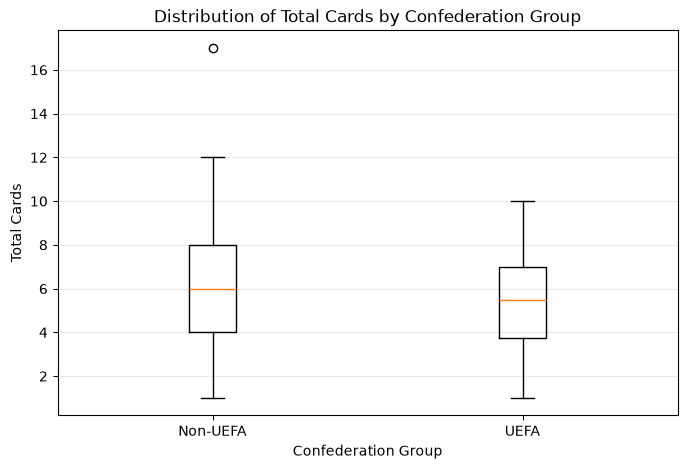

In [13]:
# Prepare data for boxplot
non_uefa_cards = sample_df[
    sample_df["Confederation Group"] == "Non-UEFA"
]["Total Cards"]

uefa_cards = sample_df[
    sample_df["Confederation Group"] == "UEFA"
]["Total Cards"]

# Create boxplot
plt.figure(figsize=(8, 5))

plt.boxplot(
    [non_uefa_cards, uefa_cards],
    tick_labels=["Non-UEFA", "UEFA"]
)

plt.title("Distribution of Total Cards by Confederation Group")
plt.xlabel("Confederation Group")
plt.ylabel("Total Cards")
plt.grid(axis="y", alpha=0.3)

plt.show()

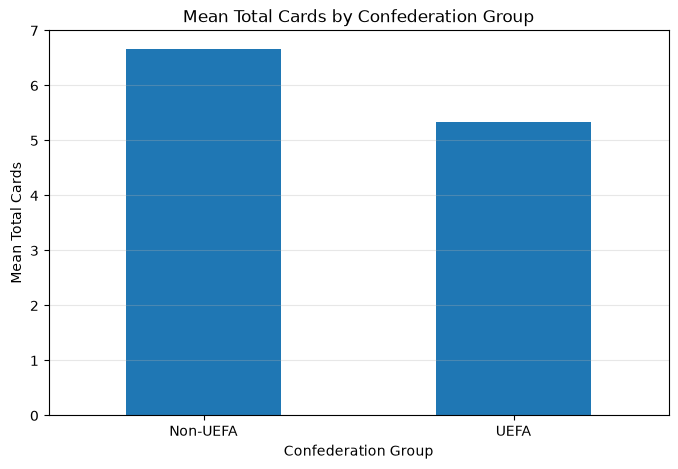

In [14]:
# Calculate group means
group_means = sample_df.groupby(
    "Confederation Group"
)["Total Cards"].mean()

# Create bar chart
plt.figure(figsize=(8, 5))

group_means.plot(kind="bar")

plt.title("Mean Total Cards by Confederation Group")
plt.xlabel("Confederation Group")
plt.ylabel("Mean Total Cards")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [15]:
from scipy import stats

# Welch independent two-sample t-test
t_stat, p_value = stats.ttest_ind(
    non_uefa_cards,
    uefa_cards,
    equal_var=False,
    alternative="greater"
)

print("Welch's t-statistic:", round(t_stat, 3))
print("p-value:", round(p_value, 5))

# Statistical decision
alpha = 0.05

if p_value < alpha:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

Welch's t-statistic: 1.315
p-value: 0.0995
Decision: Fail to reject H0


In [16]:
# Calculate sample statistics
mean_non_uefa = non_uefa_cards.mean()
mean_uefa = uefa_cards.mean()

var_non_uefa = non_uefa_cards.var(ddof=1)
var_uefa = uefa_cards.var(ddof=1)

n_non_uefa = len(non_uefa_cards)
n_uefa = len(uefa_cards)

# Mean difference
mean_difference = mean_non_uefa - mean_uefa

# Standard error
standard_error = (
    var_non_uefa / n_non_uefa +
    var_uefa / n_uefa
) ** 0.5

# Welch degrees of freedom
df_welch = (
    (var_non_uefa / n_non_uefa + var_uefa / n_uefa) ** 2
    /
    (
        (var_non_uefa / n_non_uefa) ** 2 / (n_non_uefa - 1)
        +
        (var_uefa / n_uefa) ** 2 / (n_uefa - 1)
    )
)

# 95% confidence interval
t_critical = stats.t.ppf(0.975, df_welch)
margin_error = t_critical * standard_error

ci_lower = mean_difference - margin_error
ci_upper = mean_difference + margin_error

print("Mean difference:", round(mean_difference, 2))
print("95% CI:", (round(ci_lower, 2), round(ci_upper, 2)))
print("Welch degrees of freedom:", round(df_welch, 2))

Mean difference: 1.33
95% CI: (np.float64(-0.74), np.float64(3.41))
Welch degrees of freedom: 28.2


### Interpretation of Hypothesis Test

The sample showed that Non-UEFA teams had a higher mean number of total cards than UEFA teams (6.67 compared with 5.33).

However, Welch's two-sample t-test produced a t-statistic of 1.315 and a p-value of 0.0995. Since the p-value is greater than the 0.05 significance level, the null hypothesis is not rejected.

Therefore, there is insufficient statistical evidence to conclude that Non-UEFA teams received more total cards than UEFA teams in the FIFA World Cup 2026 dataset.

The 95% confidence interval should also be considered when interpreting the difference between the two group means.

## Conclusion

This analysis investigated whether Non-UEFA teams received more total cards than UEFA teams in the FIFA World Cup 2026 dataset.

Using a proportionate stratified random sample of 36 teams, Non-UEFA teams had a mean of 6.67 total cards, compared with 5.33 for UEFA teams. The observed mean difference was 1.33 cards.

Welch's two-sample t-test produced a t-statistic of 1.315 and a p-value of 0.0995. Since the p-value is greater than the 0.05 significance level, the null hypothesis was not rejected.

The 95% confidence interval for the mean difference was [-0.74, 3.41]. Since this interval includes zero, the result also indicates that the observed difference may be due to sampling variation.

Therefore, although Non-UEFA teams had a higher average number of total cards in the sample, there is insufficient statistical evidence to conclude that Non-UEFA teams received more total cards than UEFA teams.

In [17]:
# Save cleaned Task 2 dataset
df.to_csv(
    "../data/cleaned/task2_discipline_cleaned.csv",
    index=False
)

# Save stratified sample
sample_df.to_csv(
    "../outputs/results/task2_discipline_sample.csv",
    index=False
)

# Create statistical results table
results = pd.DataFrame({
    "Measure": [
        "Non-UEFA Mean",
        "UEFA Mean",
        "Mean Difference",
        "95% CI Lower",
        "95% CI Upper",
        "Welch t-statistic",
        "Degrees of Freedom",
        "p-value"
    ],
    "Value": [
        mean_non_uefa,
        mean_uefa,
        mean_difference,
        ci_lower,
        ci_upper,
        t_stat,
        df_welch,
        p_value
    ]
})

# Save statistical results
results.to_csv(
    "../outputs/results/task2_statistical_results.csv",
    index=False
)

results.round(4)

,Measure,Value
0,Non-UEFA Mean,6.6667
1,UEFA Mean,5.3333
2,Mean Difference,1.3333
3,95% CI Lower,-0.7425
4,95% CI Upper,3.4091
5,Welch t-statistic,1.3153
6,Degrees of Freedom,28.1978
7,p-value,0.0995


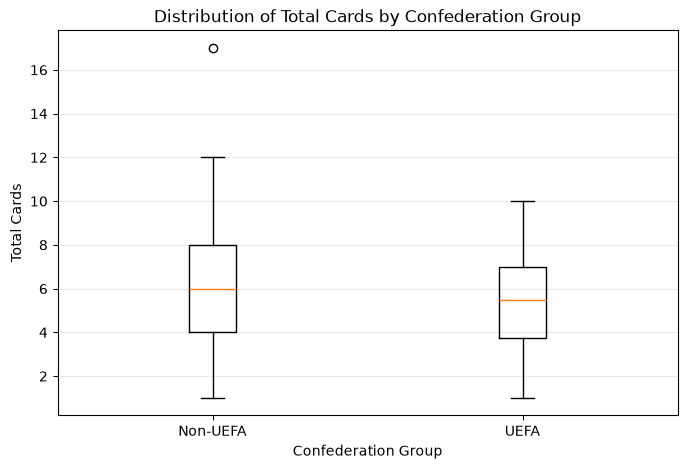

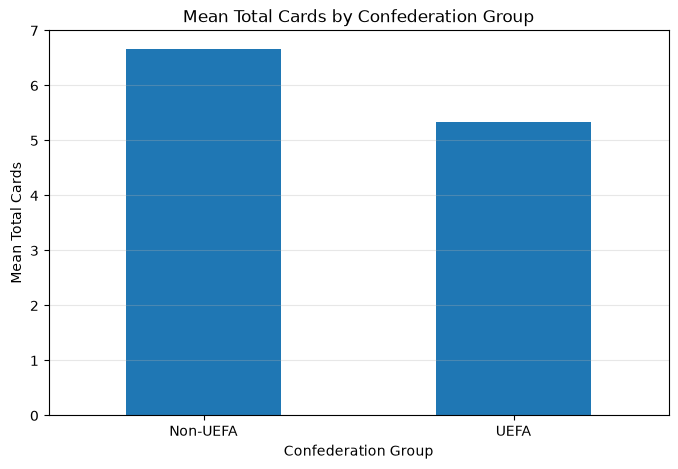

Task 2 charts saved successfully.


In [18]:
# Save Task 2 charts

# Boxplot
plt.figure(figsize=(8, 5))

plt.boxplot(
    [non_uefa_cards, uefa_cards],
    tick_labels=["Non-UEFA", "UEFA"]
)

plt.title("Distribution of Total Cards by Confederation Group")
plt.xlabel("Confederation Group")
plt.ylabel("Total Cards")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "../outputs/charts/task2_discipline_boxplot.png",
    bbox_inches="tight"
)

plt.show()


# Mean comparison bar chart
group_means = sample_df.groupby(
    "Confederation Group"
)["Total Cards"].mean()

plt.figure(figsize=(8, 5))

group_means.plot(kind="bar")

plt.title("Mean Total Cards by Confederation Group")
plt.xlabel("Confederation Group")
plt.ylabel("Mean Total Cards")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "../outputs/charts/task2_discipline_mean_comparison.png",
    bbox_inches="tight"
)

plt.show()

print("Task 2 charts saved successfully.")